# Customer Segmentation using RFM Analysis and K-Means Clustering

## Project Overview

The objective of this project is to segment customers based on their
purchasing behaviour using RFM analysis and K-Means clustering.

RFM stands for:

- Recency - How recently a customer made a purchase
- Frequency - How often a customer makes a purchase
- Monetary - How much a customer spends

The identified customer segments will be analysed further to understand
customer behaviour and provide suitable business recommendations.

In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [32]:
df = pd.read_excel("C:/Users/hemas/OneDrive/Desktop/Python/customer_dataset.xlsx")
df.head()

,Order_ID,Customer_ID,Date,Age,Gender,City,Product_Category,Unit_Price,Quantity,Discount_Amount,Total_Amount,Payment_Method,Device_Type,Session_Duration_Minutes,Pages_Viewed,Is_Returning_Customer,Delivery_Time_Days,Customer_Rating
0,ORD_000001-1,CUST_00001,2023-05-29,40,Male,Ankara,Books,29.18,1,0.00,29.18,Digital Wallet,Mobile,14,9,True,13,4
1,ORD_000001-2,CUST_00001,2023-10-12,40,Male,Ankara,Home & Garden,644.40,1,138.05,506.35,Credit Card,Desktop,14,8,True,6,2
2,ORD_000001-3,CUST_00001,2023-12-05,40,Male,Ankara,Sports,332.82,5,0.00,1664.10,Credit Card,Mobile,15,10,True,9,4
3,ORD_000002-1,CUST_00002,2023-05-11,33,Male,Istanbul,Food,69.30,5,71.05,275.45,Digital Wallet,Desktop,16,13,True,4,4
4,ORD_000002-2,CUST_00002,2023-06-16,33,Male,Istanbul,Beauty,178.15,3,0.00,534.45,Credit Card,Mobile,14,7,True,6,4


## 1.Initial Inspection

In [33]:
df.shape

(17049, 18)

In [34]:
df.columns

Index(['Order_ID', 'Customer_ID', 'Date', 'Age', 'Gender', 'City',
       'Product_Category', 'Unit_Price', 'Quantity', 'Discount_Amount',
       'Total_Amount', 'Payment_Method', 'Device_Type',
       'Session_Duration_Minutes', 'Pages_Viewed', 'Is_Returning_Customer',
       'Delivery_Time_Days', 'Customer_Rating'],
      dtype='str')

In [35]:
df.dtypes

Order_ID                               str
Customer_ID                            str
Date                        datetime64[us]
Age                                  int64
Gender                                 str
City                                   str
Product_Category                       str
Unit_Price                         float64
Quantity                             int64
Discount_Amount                    float64
Total_Amount                       float64
Payment_Method                         str
Device_Type                            str
Session_Duration_Minutes             int64
Pages_Viewed                         int64
Is_Returning_Customer                 bool
Delivery_Time_Days                   int64
Customer_Rating                      int64
dtype: object

In [36]:
df.isnull().sum()

Order_ID                    0
Customer_ID                 0
Date                        0
Age                         0
Gender                      0
City                        0
Product_Category            0
Unit_Price                  0
Quantity                    0
Discount_Amount             0
Total_Amount                0
Payment_Method              0
Device_Type                 0
Session_Duration_Minutes    0
Pages_Viewed                0
Is_Returning_Customer       0
Delivery_Time_Days          0
Customer_Rating             0
dtype: int64

In [37]:
df.duplicated().sum()

np.int64(0)

## 2. Descriptive Analysis

Descriptive analysis is performed to understand customer purchasing behaviour before applying clustering.

The main behavioural metrics considered are:

- Average Purchase Value – the average amount spent per order.
- Purchase Frequency – the number of orders made by each customer.
- Customer Lifetime Value – the total amount spent by each customer.

In [38]:
customer_analysis = df.groupby("Customer_ID").agg(
    Average_Purchase_Value = ("Total_Amount","mean"),
    Purchase_Frequency = ("Order_ID","count"),
    Customer_Lifetime_Value = ("Total_Amount","sum")
)
customer_analysis.head()

,Average_Purchase_Value,Purchase_Frequency,Customer_Lifetime_Value
Customer_ID,,,
CUST_00001,733.210000,3,2199.63
CUST_00002,404.950000,2,809.90
CUST_00003,1515.405000,2,3030.81
CUST_00004,383.220000,1,383.22
CUST_00005,807.576667,3,2422.73


### Summary Statistics

Summary statistics are calculated to understand the distribution of customer purchase behaviour.

In [39]:
customer_analysis.describe()

,Average_Purchase_Value,Purchase_Frequency,Customer_Lifetime_Value
count,5000.000000,5000.000000,5000.000000
mean,1262.886447,3.409800,4355.810518
std,1539.039257,2.181746,5274.546636
min,14.280000,1.000000,14.280000
25%,387.121667,2.000000,889.410000
50%,794.481667,3.000000,2493.925000
75%,1550.695000,5.000000,5796.297500
max,25314.075000,10.000000,50628.150000


In [40]:
print("Total Customers:",customer_analysis.shape[0])

Total Customers: 5000


### Highest Value Customers

The customers with the highest total spending are identified to understand high-value customer behaviour.

In [41]:
customer_analysis.sort_values("Customer_Lifetime_Value",ascending = False).head(10)

,Average_Purchase_Value,Purchase_Frequency,Customer_Lifetime_Value
Customer_ID,,,
CUST_01573,25314.075000,2,50628.15
CUST_00197,4732.423000,10,47324.23
CUST_03795,14160.006667,3,42480.02
CUST_00154,4161.383000,10,41613.83
CUST_04219,5076.048750,8,40608.39
CUST_03149,6639.101667,6,39834.61
CUST_03923,3861.082000,10,38610.82
CUST_01164,4093.601111,9,36842.41
CUST_01816,4061.918889,9,36557.27


In [42]:
customer_analysis[["Average_Purchase_Value","Purchase_Frequency","Customer_Lifetime_Value"]].mean()

Average_Purchase_Value     1262.886447
Purchase_Frequency            3.409800
Customer_Lifetime_Value    4355.810518
dtype: float64

## 3. Feature Selection

For customer segmentation, behavioural features are selected based on customer purchasing patterns.

The RFM features are selected for clustering:

- Recency – how recently the customer made a purchase.
- Frequency – how often the customer makes purchases.
- Monetary – how much the customer has spent.

These features provide a useful representation of customer engagement and purchasing value.

In [43]:
reference_date = df["Date"].max()

rfm = df.groupby("Customer_ID").agg(
    Recency=("Date", lambda x: (reference_date - x.max()).days),
    Frequency=("Order_ID","count"),
    Monetary=("Total_Amount","sum")
)
rfm.head()

,Recency,Frequency,Monetary
Customer_ID,,,
CUST_00001,111,3,2199.63
CUST_00002,283,2,809.90
CUST_00003,82,2,3030.81
CUST_00004,41,1,383.22
CUST_00005,278,3,2422.73


In [44]:
rfm.shape

(5000, 3)

In [45]:
rfm.describe()

,Recency,Frequency,Monetary
count,5000.000000,5000.000000,5000.000000
mean,124.716400,3.409800,4355.810518
std,108.050972,2.181746,5274.546636
min,0.000000,1.000000,14.280000
25%,38.000000,2.000000,889.410000
50%,93.000000,3.000000,2493.925000
75%,184.000000,5.000000,5796.297500
max,449.000000,10.000000,50628.150000


### Selected Features for Clustering

Recency, Frequency, and Monetary are selected as the main features for K-Means clustering.

In [46]:
features = rfm[["Recency","Frequency","Monetary"]]
features.head()

,Recency,Frequency,Monetary
Customer_ID,,,
CUST_00001,111,3,2199.63
CUST_00002,283,2,809.90
CUST_00003,82,2,3030.81
CUST_00004,41,1,383.22
CUST_00005,278,3,2422.73


## 4. Data Standardisation

The selected RFM features have different scales. StandardScaler is used
to standardise the features so that each feature contributes fairly to
the K-Means clustering process.

In [47]:
from sklearn.preprocessing import StandardScaler

In [48]:
scalar = StandardScaler()
rfm_scaled = scalar.fit_transform(features)
rfm_scaled[:5]

array([[-0.12695649, -0.18784999, -0.40883062],
       [ 1.46504402, -0.64624431, -0.67233554],
       [-0.39537518, -0.64624431, -0.25123165],
       [-0.77486367, -1.10463864, -0.75323779],
       [ 1.41876494, -0.18784999, -0.36652891]])

In [49]:
rfm_scaled.shape

(5000, 3)

### Observation

The RFM features were standardised using StandardScaler because Recency,
Frequency, and Monetary values have different numerical scales.
Standardisation prevents a feature with larger values from dominating
the clustering process.

## 5. Finding the Optimal Number of Clusters

The Elbow Method is used to determine the appropriate number of
customer segments for K-Means clustering.

The method calculates the Within-Cluster Sum of Squares (WCSS), also
known as inertia, for different numbers of clusters. The point where
the decrease in inertia starts to slow down is considered the elbow
point and is used to select the optimal number of clusters.

In [50]:
from sklearn.cluster import KMeans

In [51]:
inertia = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(rfm_scaled)
    inertia.append(kmeans.inertia_)

inertia

[9137.289815402411,
 6060.624490161954,
 4760.878707355952,
 4065.137555957838,
 3513.151315709396,
 3016.768278666369,
 2766.7776512502846,
 2551.6710582893475,
 2389.6061385196335]

### Elbow Method Visualization

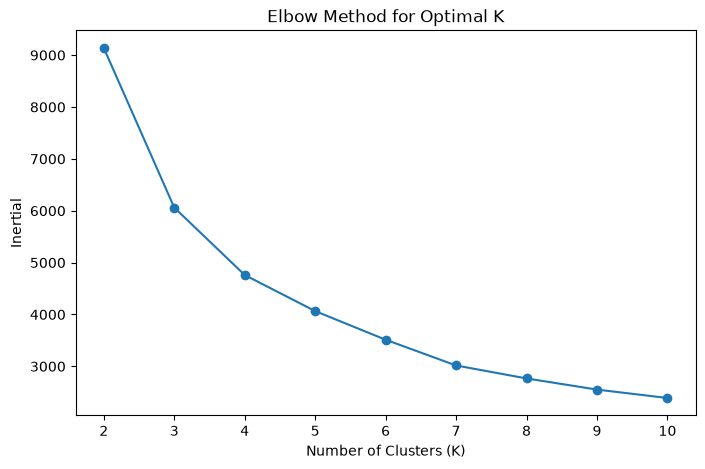

In [52]:
plt.figure(figsize=(8,5))
plt.plot(range(2,11), inertia, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertial")
plt.title("Elbow Method for Optimal K")
plt.show()

### Observation

The Elbow Method shows a sharp decrease in inertia from K=2 to K=4. After K=4, the decrease in inertia becomes smaller and more gradual. Therefore, K=4 is selected as the optimal number of clusters for customer segmentation.

In [53]:
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
clusters = kmeans.fit_predict(rfm_scaled)
clusters[:10]

array([0, 2, 0, 0, 2, 2, 0, 0, 0, 0], dtype=int32)

In [54]:
customer_data = features.copy()
customer_data['Cluster'] = clusters
customer_data.head()

,Recency,Frequency,Monetary,Cluster
Customer_ID,,,,
CUST_00001,111,3,2199.63,0
CUST_00002,283,2,809.90,2
CUST_00003,82,2,3030.81,0
CUST_00004,41,1,383.22,0
CUST_00005,278,3,2422.73,2


In [55]:
customer_data.shape

(5000, 4)

In [56]:
customer_data["Cluster"].value_counts().sort_index()

Cluster
0    2381
1     344
2    1181
3    1094
Name: count, dtype: int64

In [57]:
cluster_profile = customer_data.groupby("Cluster")[["Recency","Frequency","Monetary"]].mean()
cluster_profile.round(2)

,Recency,Frequency,Monetary
Cluster,,,
0,83.30,2.54,2517.71
1,67.68,6.15,19120.79
2,287.52,1.81,2001.26
3,57.04,6.18,6255.35


### Cluster Profiling – Observation

The customer segments show clear differences in purchasing behaviour.

- Cluster 0 represents regular customers with moderate spending and purchase frequency.
- Cluster 1 represents high-value customers because they have high purchase frequency and the highest monetary value.
- Cluster 2 represents at-risk customers because they have the highest recency and the lowest purchase frequency.
- Cluster 3 represents loyal customers because they purchase recently and frequently with relatively high spending.

These segments can help the business create different marketing strategies for different types of customers.

## Recency vs Monetary Scatter plot

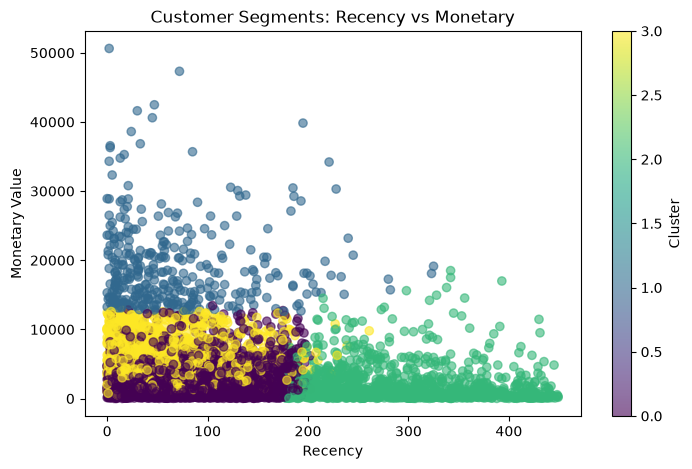

In [58]:
plt.figure(figsize=(8,5))
plt.scatter(
    customer_data["Recency"],
    customer_data["Monetary"],
    c=customer_data["Cluster"],
    cmap="viridis",
    alpha=0.6)
plt.xlabel("Recency")
plt.ylabel("Monetary Value")
plt.title("Customer Segments: Recency vs Monetary")
plt.colorbar(label = 'Cluster')
plt.show()

### Observation – Recency vs Monetary

- Customers with **low recency values** are generally more active recently and show a wide range of monetary values.
- A small group of customers has **very high monetary value**, indicating high-value customers who have spent significantly more.
- Customers with **high recency values** generally have lower monetary values, which may indicate less active or inactive customers.
- The clusters show that customers can be differentiated based on both **how recently they purchased and how much they spent**.
- This segmentation can help businesses target **high-value active customers** with loyalty offers and re-engage customers who have not purchased recently.

## Frequency vs Monetary Scatter plot

<function matplotlib.pyplot.show(close=None, block=None)>

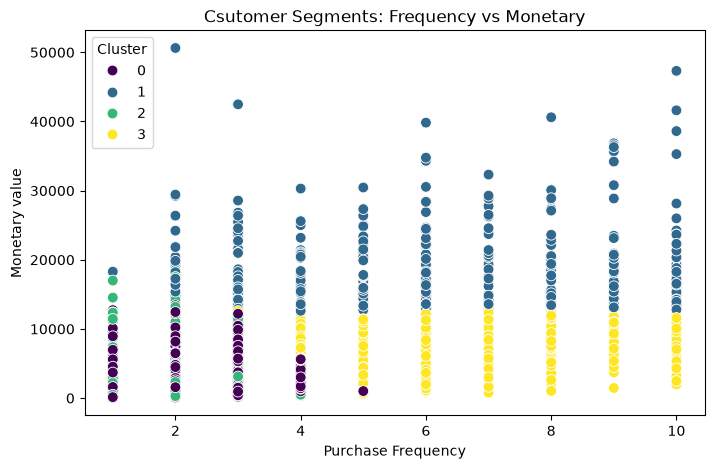

In [59]:
plt.figure(figsize=(8,5))
sns.scatterplot(
    data=customer_data,
    x="Frequency",
    y="Monetary",
    hue="Cluster",
    palette="viridis",
    s=60)
plt.title("Csutomer Segments: Frequency vs Monetary")
plt.xlabel("Purchase Frequency")
plt.ylabel("Monetary value")
plt.show

### Observation

- Customers with higher purchase frequency generally show higher monetary values.
- The chart shows that customers with low purchase frequency are mostly concentrated at lower spending levels.
- Some customers have both high purchase frequency and high monetary value, making them important high-value customers.
- The clusters help separate customers based on their purchasing frequency and total spending.
- High-frequency and high-spending customers can be targeted with loyalty programs and exclusive offers.

### Customer Segment Profiles

- **Cluster 0 – Regular Customers:** These customers have moderate recency, purchase frequency and monetary value. They can be encouraged with personalized offers to increase their spending.

- **Cluster 1 – High-Value Customers:** These customers have high purchase frequency and the highest monetary value. They are the most valuable segment and should be retained through loyalty rewards and exclusive offers.

- **Cluster 2 – At-Risk Customers:** These customers have the highest recency and lowest purchase frequency. They may be becoming inactive, so win-back campaigns and special discounts can be used to encourage them to return.

- **Cluster 3 – Frequent Customers:** These customers purchase frequently and have relatively recent purchases, but their monetary value is lower than Cluster 1. Cross-selling and upselling can help increase their spending.

## Number of Customers per each Cluster

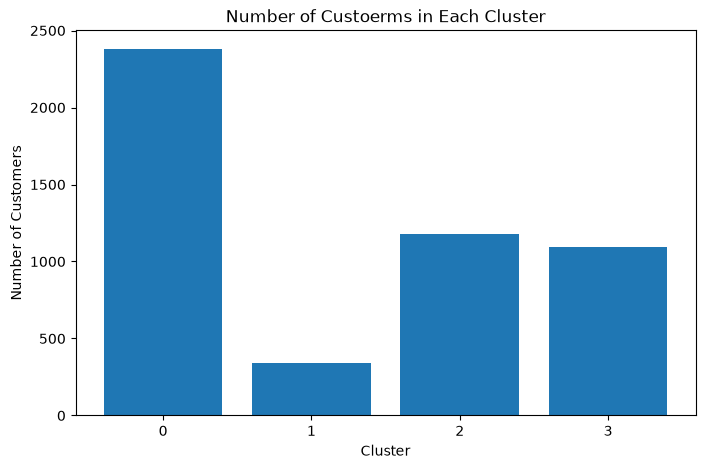

In [60]:
cluster_counts = customer_data['Cluster'].value_counts().sort_index()
plt.figure(figsize=(8,5))
plt.bar(cluster_counts.index.astype(str), cluster_counts.values)
plt.title("Number of Custoerms in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.show()

### Observation

- **Cluster 0** has the highest number of customers, with around **2,380 customers**.
- **Cluster 1** is the smallest segment, with around **340 customers**, but it represents the highest-value customers based on the previous cluster profile.
- **Cluster 2** has around **1,180 customers**, making it the second-largest segment.
- **Cluster 3** has around **1,100 customers** and represents frequent customers with moderate spending.
- The customer distribution is not equal across the clusters, showing that different customer groups have different purchasing behaviours.

## Final Insights

- **Cluster 0** has the highest number of customers. These customers have moderate purchase frequency and spending, so there is a good opportunity to increase their spending through offers and product recommendations.

- **Cluster 1** has fewer customers, but they have the **highest monetary value and high purchase frequency**. These are the most valuable customers, so the business should focus on retaining them through loyalty rewards and special offers.

- **Cluster 2** has the **highest recency and lowest purchase frequency**. This shows that these customers have not purchased recently and may be at risk of becoming inactive. The business can target them with discounts and win-back offers.

- **Cluster 3** has high purchase frequency and recent purchases, but their spending is lower than Cluster 1. The business can use bundle offers and cross-selling to increase their spending.

## Marketing Recommendations

- Give **loyalty rewards and exclusive offers** to Cluster 1 customers.
- Send **discounts and personalised offers** to Cluster 2 customers to bring them back.
- Use **cross-selling and bundle offers** for Cluster 3 customers.
- Use **personalised recommendations and promotions** for the large Cluster 0 group.

## Conclusion

Customer segmentation helped me understand that all customers do not have the same purchasing behaviour. By using Recency, Frequency and Monetary values with K-Means clustering, I was able to divide customers into different groups. This can help the business use different marketing strategies for different types of customers.